# 1 · Bits, symbols and noise

**NR link-level simulation from zero**, notebook 1 · [All notebooks](README.md) · [Glossary](GLOSSARY.md) · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/HelloSYQ/Claude/blob/HEAD/notebooks/learn/01_bits_symbols_and_noise.ipynb)

**In one sentence:** the transmitter turns groups of bits into *symbols* (arrows with a length and an angle), noise nudges every arrow at random, and the receiver guesses which arrow was sent; sometimes it guesses wrong.

**You will learn**
- why a radio signal is described by complex numbers, and why that is less scary than it sounds;
- how two bits become one QPSK symbol, by hand and with `nrdlsim`;
- what noise does to symbols, and how to count the bit errors it causes;
- how the receiver can say how *sure* it is about each bit.

**You need** notebook 0 (decibels, SNR). **Time:** about 20 minutes.

**How to use it.** Run the cells from top to bottom with Shift+Enter. The outputs are stored, so you can also just read.

In [1]:
# Setup: make the nrdlsim package importable, then import the basics.
# (On Google Colab this installs nrdlsim from GitHub the first time.)
import os, sys, subprocess, importlib.util
if importlib.util.find_spec("nrdlsim") is None:
    root = os.getcwd()
    while root != os.path.dirname(root) and not os.path.isdir(os.path.join(root, "nrdlsim")):
        root = os.path.dirname(root)
    if os.path.isdir(os.path.join(root, "nrdlsim")):
        sys.path.insert(0, root)              # running inside the repository
    else:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/HelloSYQ/Claude"], check=True)

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

def check(question, answer, expected, tol):
    """Say whether an answer is within tol of the expected value."""
    if answer is None:
        print(f"{question}: put your answer in place of None and run the cell again")
    elif abs(answer - expected) <= tol:
        print(f"{question}: yes, {answer} is right")
    else:
        print(f"{question}: not quite, try again (or open the answer below)")

## 1 · A radio wave is an arrow

A transmitter sends a sine wave at its carrier frequency, 3.5 GHz in our set-up. To carry information it changes two things about the wave:

- its **amplitude**: how big it is;
- its **phase**: how far along its cycle it is, a shift in time.

Two numbers describe the wave at each moment, and engineers store them as one **complex number**: an arrow whose length is the amplitude and whose angle is the phase. Three facts about complex numbers are all you need here:

1. `a + 1j*b` is the arrow to the point (a, b); in Python, `1j` is the imaginary unit.
2. `abs(z)` is the arrow's length and `np.angle(z)` its angle.
3. Multiplying two complex numbers multiplies their lengths and adds their angles, so multiplication **scales and rotates** an arrow. That is exactly what the radio channel does to a signal (notebook 5).

Below are two waves, and the same two waves as arrows.

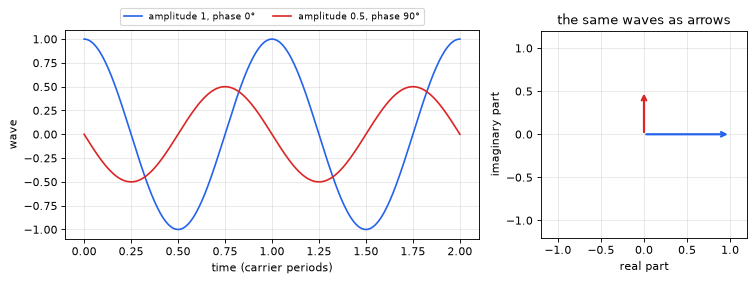

red arrow: length 0.5 | angle 90.0 degrees


In [2]:
t = np.linspace(0, 2, 400)                       # time, in periods of the carrier
waves = {"amplitude 1, phase 0°": 1.0 * np.exp(1j * 0),
         "amplitude 0.5, phase 90°": 0.5 * np.exp(1j * np.pi / 2)}

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [2, 1]})
for (name, z), color in zip(waves.items(), ("#2563eb", "#dc2626")):
    a1.plot(t, abs(z) * np.cos(2 * np.pi * t + np.angle(z)), color=color, label=name)
    a2.annotate("", xy=(z.real, z.imag), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=color, lw=2))
a1.set_xlabel("time (carrier periods)"); a1.set_ylabel("wave")
a1.legend(fontsize=8, ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0))
a2.set_xlim(-1.2, 1.2); a2.set_ylim(-1.2, 1.2); a2.set_aspect("equal")
a2.set_xlabel("real part"); a2.set_ylabel("imaginary part"); a2.set_title("the same waves as arrows")
plt.show()

z = 0.5 * np.exp(1j * np.pi / 2)
print("red arrow: length", abs(z), "| angle", np.degrees(np.angle(z)), "degrees")

**What you see:** the red wave is half as tall as the blue one and shifted by a quarter of a period; its arrow is half as long and turned by 90°. From here on we only draw arrows.

## 2 · Bits to symbols, by hand: QPSK

The transmitter sends one arrow at a time, each for a short moment called a **symbol**. If it can choose among 4 arrows, each symbol carries 2 bits, because 4 = 2².

**QPSK** (quadrature phase-shift keying) uses 4 arrows of the same length, one in each quarter of the plane:

- the first bit picks the sign of the horizontal (real) part: 0 gives +, 1 gives −;
- the second bit picks the sign of the vertical (imaginary) part, the same way;
- dividing by √2 makes every arrow 1 long, so the average **symbol energy** is 1.

The set of allowed arrows is the **constellation**. Neighbouring points differ in exactly one bit (*Gray mapping*), so a small mistake costs one bit, not two.

[ 0.707+0.707j  0.707-0.707j -0.707+0.707j -0.707-0.707j]


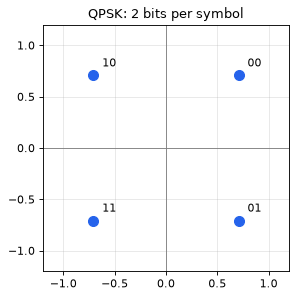

In [3]:
def qpsk(bits):
    pairs = np.asarray(bits).reshape(-1, 2)           # two bits per symbol
    return ((1 - 2 * pairs[:, 0]) + 1j * (1 - 2 * pairs[:, 1])) / np.sqrt(2)

bits = np.array([0, 0,  0, 1,  1, 0,  1, 1])
symbols = qpsk(bits)
print(np.round(symbols, 3))

fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(symbols.real, symbols.imag, s=80, color="#2563eb")
for s, pair in zip(symbols, bits.reshape(-1, 2)):
    ax.annotate("".join(map(str, pair)), (s.real, s.imag), textcoords="offset points", xytext=(8, 8))
ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_aspect("equal")
ax.set_title("QPSK: 2 bits per symbol")
plt.show()

The simulator's modulator, `nrdlsim.modulation.Modulator`, follows TS 38.211, the 5G specification of the physical layer. For QPSK it produces exactly the same arrows:

In [4]:
from nrdlsim.modulation import Modulator

rng = np.random.default_rng(1)
many_bits = rng.integers(0, 2, 2000)
print("same as nrdlsim:", np.allclose(qpsk(many_bits), Modulator(2).modulate(many_bits)))

same as nrdlsim: True


## 3 · Noise

Every receiver adds **noise**: tiny random disturbances, caused for example by the thermal motion of electrons in its electronics. The standard model is **additive white Gaussian noise (AWGN)**: each received symbol is the sent symbol plus a random arrow whose two parts are independent Gaussian ("bell curve") numbers.

The noise strength is its power, N₀. Our symbols have power 1, so

$$\text{SNR} = \frac{1}{N_0} \qquad\Longleftrightarrow\qquad N_0 = 10^{-\text{SNR}_\text{dB}/10}$$

where SNR is the ratio and SNR<sub>dB</sub> the same thing in decibels. Each part of the noise, real and imaginary, gets half of N₀.

In [5]:
def add_noise(symbols, snr_db, rng):
    n0 = 10 ** (-snr_db / 10)                        # noise power, for symbols of power 1
    noise = np.sqrt(n0 / 2) * (rng.standard_normal(symbols.size)
                               + 1j * rng.standard_normal(symbols.size))
    return symbols + noise

sent = qpsk(rng.integers(0, 2, 2 * 1000))            # 1000 random QPSK symbols

**Predict first:** below are 1000 received symbols at 20, 10 and 0 dB. At which SNR will some of them land in the wrong quarter of the plane?

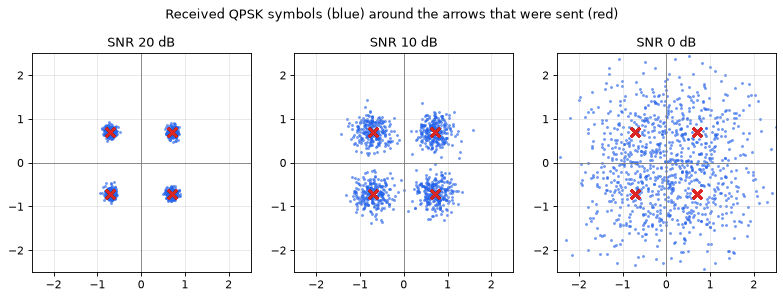

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, snr in zip(axes, (20, 10, 0)):
    received = add_noise(sent, snr, rng)
    ax.scatter(received.real, received.imag, s=3, alpha=0.5, color="#2563eb")
    ax.scatter(sent.real, sent.imag, s=60, color="#dc2626", marker="x")
    ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
    ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5); ax.set_aspect("equal")
    ax.set_title(f"SNR {snr} dB")
plt.suptitle("Received QPSK symbols (blue) around the arrows that were sent (red)")
plt.show()

**What you see:** at 20 dB each arrow arrives as a tight cloud. At 10 dB the clouds spread but stay in their quarter. At 0 dB the noise is as strong as the signal: the clouds reach across the axes, and some symbols land in the wrong quarter.

**Play with it.** If you run the notebook yourself, the next cell gives you an SNR slider. It needs the `ipywidgets` package, which Colab has.

In [7]:
def show_received(snr_db=10.0):
    received = add_noise(sent, snr_db, np.random.default_rng(0))
    plt.figure(figsize=(4, 4))
    plt.scatter(received.real, received.imag, s=3, alpha=0.5)
    plt.axhline(0, color="gray", lw=0.8); plt.axvline(0, color="gray", lw=0.8)
    plt.xlim(-2.5, 2.5); plt.ylim(-2.5, 2.5); plt.gca().set_aspect("equal")
    plt.title(f"SNR {snr_db:.0f} dB"); plt.show()

try:
    import ipywidgets
    ipywidgets.interact(show_received,
                        snr_db=ipywidgets.FloatSlider(value=10, min=-5, max=30, step=1))
except ImportError:
    print("ipywidgets is not installed here, so there is no slider.\n"
          "Try other SNRs with, for example, show_received(snr_db=5).")

ipywidgets is not installed here, so there is no slider.
Try other SNRs with, for example, show_received(snr_db=5).


## 4 · Deciding, and counting errors

The receiver doesn't know which arrow was sent. For QPSK its best guess is the nearest arrow, which comes down to signs: a positive real part means the first bit was 0, a negative one means 1, and the same for the imaginary part and the second bit.

A **bit error** is a bit decided wrongly. The **bit error rate (BER)** is the fraction of bits decided wrongly.

For QPSK over AWGN, theory gives the BER exactly:

$$\text{BER} = Q\left(\sqrt{\text{SNR}}\right)$$

with the SNR as a ratio, not in dB. Q(x) is the chance that a standard Gaussian number exceeds x: here, the chance that the noise pushes a symbol across an axis. Let's measure the BER and compare.

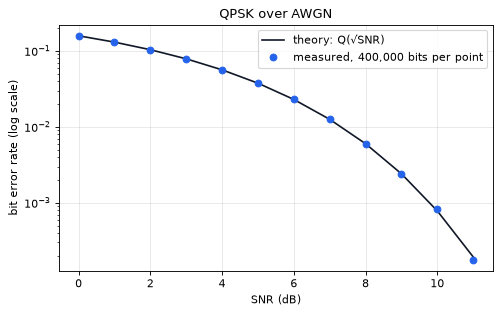

SNR  0 dB: about 1 bit in     6 is wrong
SNR  6 dB: about 1 bit in    43 is wrong
SNR 10 dB: about 1 bit in 1,278 is wrong


In [8]:
from math import erfc, sqrt

def decide_qpsk(received):
    bits = np.empty((received.size, 2), dtype=int)
    bits[:, 0] = received.real < 0                   # first bit: sign of the real part
    bits[:, 1] = received.imag < 0                   # second bit: sign of the imaginary part
    return bits.reshape(-1)

def q_function(x):
    return 0.5 * erfc(x / sqrt(2))

snrs = np.arange(0, 12)
n_bits = 400_000
tx_bits = rng.integers(0, 2, n_bits)
tx = qpsk(tx_bits)
ber_measured = [np.mean(decide_qpsk(add_noise(tx, s, rng)) != tx_bits) for s in snrs]
ber_theory = [q_function(sqrt(10 ** (s / 10))) for s in snrs]

plt.figure(figsize=(7, 4))
plt.semilogy(snrs, ber_theory, "-", color="#111827", label="theory: Q(√SNR)")
plt.semilogy(snrs, ber_measured, "o", color="#2563eb", label=f"measured, {n_bits:,} bits per point")
plt.xlabel("SNR (dB)"); plt.ylabel("bit error rate (log scale)"); plt.legend()
plt.title("QPSK over AWGN")
plt.show()
for s in (0, 6, 10):
    print(f"SNR {s:2d} dB: about 1 bit in {1 / ber_theory[s]:5,.0f} is wrong")

**What you see**

- The measured points sit on the theory curve.
- The vertical axis is logarithmic: each grid line down means 10 times fewer errors. The error rate falls steeply, from about one bit in six at 0 dB to about one in 1300 at 10 dB.
- Even one error in a thousand bits is useless for data. An internet packet of 1500 bytes holds 12 000 bits, so it would almost never arrive intact. Real systems therefore add redundancy, an *error-correcting code*, that lets the receiver repair errors (notebook 3).

## 5 · How sure is the receiver?

A point far from the axes was almost certainly sent from that quarter; a point close to an axis could easily have come from the other side. Error-correcting decoders work much better if they know this. So instead of a hard 0 or 1, the receiver passes on a **log-likelihood ratio (LLR)** for each bit:

- positive means "probably 0", negative means "probably 1";
- the larger its size, the surer the receiver is.

Formally, LLR = log P(bit = 0 | what was received) − log P(bit = 1 | what was received). `Modulator.demodulate_llr` computes it for any constellation, from the received symbols and the noise power.

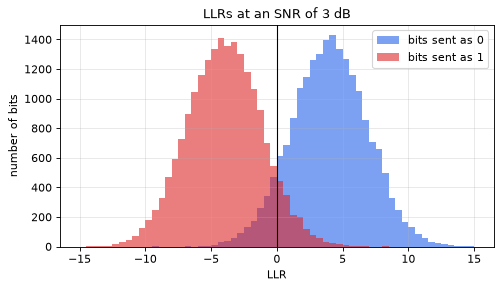

LLR signs give the same decisions as section 4: True


In [9]:
snr = 3
n0 = 10 ** (-snr / 10)
bits3 = rng.integers(0, 2, 40_000)
received3 = add_noise(qpsk(bits3), snr, rng)
llr = Modulator(2).demodulate_llr(received3, n0)

plt.figure(figsize=(7, 3.6))
bins = np.linspace(-15, 15, 61)
plt.hist(llr[bits3 == 0], bins, alpha=0.6, color="#2563eb", label="bits sent as 0")
plt.hist(llr[bits3 == 1], bins, alpha=0.6, color="#dc2626", label="bits sent as 1")
plt.axvline(0, color="black", lw=1)
plt.xlabel("LLR"); plt.ylabel("number of bits"); plt.title(f"LLRs at an SNR of {snr} dB")
plt.legend()
plt.show()
print("LLR signs give the same decisions as section 4:",
      np.array_equal((llr < 0).astype(int), decide_qpsk(received3)))

**What you see:** two humps. Bits sent as 0 mostly get positive LLRs, bits sent as 1 negative ones. Where the humps overlap, around 0, the receiver is unsure, and that is where its errors are. A decoder (notebook 3) trusts a bit with a large LLR and is ready to flip a bit whose LLR is close to 0.

## 6 · Check yourself

**1.** About what SNR, in dB, makes 1 bit in 1000 wrong? Use the plot, or try values in `q_function(sqrt(10 ** (snr / 10)))`.

In [10]:
answer = None
check("SNR for a BER of 1/1000 (dB)", answer, expected=9.8, tol=0.5)

SNR for a BER of 1/1000 (dB): put your answer in place of None and run the cell again


<details><summary>Answer</summary>

About 9.8 dB: `q_function(sqrt(10 ** (9.8 / 10)))` is 0.001.

</details>

**2.** At 10 dB, how many of the 12 000 bits of a 1500-byte packet do you expect to be wrong?

In [11]:
answer = None
check("wrong bits in 12 000 at 10 dB", answer, expected=12_000 * q_function(sqrt(10)), tol=1.5)

wrong bits in 12 000 at 10 dB: put your answer in place of None and run the cell again


<details><summary>Answer</summary>

About 9: 12 000 × Q(√10) ≈ 12 000 × 0.00078 ≈ 9.4.

</details>

**3.** Swap the roles of the two bits in `qpsk`, so the first bit sets the imaginary part. Does the BER change? Why?

<details><summary>Answer</summary>

No. The noise is equally strong in every direction, so it doesn't matter which bit goes on which axis.

</details>

## Where in the code

- `nrdlsim/modulation.py`: `Modulator.modulate` (bits to symbols) and `Modulator.demodulate_llr` (received symbols to LLRs), for QPSK up to 1024QAM.
- `tests/validate_ber.py` repeats section 4's comparison with theory for every constellation.

## Going further

- 3GPP TS 38.211, clause 5.1 (*Modulation mapper*): the exact mappings 5G uses, QPSK to 1024QAM.
- The QPSK chapter of any digital-communications textbook, for example J. G. Proakis, *Digital Communications*.

## Recap

- A radio wave's amplitude and phase form a complex number: an arrow.
- A **symbol** is one arrow. **QPSK** has 4 arrows, so it carries 2 bits per symbol.
- **AWGN** adds a random arrow to every symbol; the **SNR** sets its size.
- The receiver picks the nearest arrow. The **BER** falls steeply with the SNR but never reaches zero.
- **LLRs** tell the decoder how sure each bit is.

**Words you met:** amplitude, phase, complex number, symbol, constellation, QPSK, Gray mapping, AWGN, N₀, bit error rate, LLR. All are in the [glossary](GLOSSARY.md).

**Next:** [notebook 2](02_more_bits_per_symbol.ipynb), packing more bits into each symbol, and the price in SNR.